> Notebook-friendly copy of `part-II/3.5-wildfire-susceptibility-mapping-exercises.ipynb`, generated by `tools/make_live.py`. Edit the book notebook, not this file.

In [1]:
# --- environment setup (generated, not part of the lesson) ---
# Colab and Kaggle do not ship every package this notebook imports.
# This is a no-op in an environment that is already set up.
import importlib.util
import subprocess
import sys

for module, package in {"geopandas": "geopandas", "pooch": "pooch"}.items():
    if importlib.util.find_spec(module) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", package], check=True)

# 3.5) (Exercises) Wildfire Susceptibility Mapping

---



**Credits**

This online tutorial would not be possible without invaluable contributions from [Andrea Trucchia](https://www.researchgate.net/profile/Andrea-Trucchia) (reduced data, methods), [Giorgio Meschi](https://www.linkedin.com/in/giorgio-meschi-86216b180/) (code, methods), and [Marj Tonini](https://www.researchgate.net/profile/Marj-Tonini-2) (presentation, methods). The methodology builds upon the following article:

[Trucchia, A.; Meschi, G.; Fiorucci, P.; Gollini, A.; Negro, D., Defining Wildfire Susceptibility Maps in Italy for Understanding Seasonal Wildfire Regimes at the National Level, *Fire*, (2022)](https://www.mdpi.com/2571-6255/5/1/30)

which generalizes the study below from the Liguria region (our case study) to all of Italy:

[Tonini, Marj, et al. "A machine learning-based approach for wildfire susceptibility mapping. The case study of the Liguria region in Italy." *Geosciences* 10.3 (2020): 105.](https://www.mdpi.com/2076-3263/10/3/105)



---

In week 3's final notebook, we will train classifiers on real [wildfire](https://en.wikipedia.org/wiki/Wildfire) data to map the fire risk in different regions of Italy. To keep the data size manageable, we will focus on the coastal [Liguria region](https://en.wikipedia.org/wiki/Liguria) that experiences a lot of wildfires, especially during the winter.

**🎯 Learning objectives**

- Use classification methods for environmental risk analysis
- Train classifiers on real data to map wildfire susceptibility in Liguria, Italy
- Benchmark the classifiers with scikit-learn's confusion matrix
- Run a sensitivity analysis to see how predictions change with season and input selection

## Machine Learning for Environmental Risk Analysis

For environmental sciences practioners, one of the scenarios where machine learning can be particularly useful is risk analysis. Environmental risk analysis involves predicting where potential hazards may occur; it also involves understanding why some regions are more vulnerable to hazards than others. Machine learning models can be useful for these tasks because they can analyze large datasets containing different environmental predictors (e.g., weather conditions, soil conditions etc.) in an effective manner. By learning the hidden links between predictors and hazard risks, we may also gain new insights on what predictors or patterns are useful for creating early hazard warning systems.

In this exercise, we ask you to use the machine learning classifiers we learned in this chapter to recreate wildfire susceptibility maps for the Liguria region of Italy. The basic idea is to use ML classifiers to analyze a dataset with observations in weather conditions, vegetation cover, and topography information. The goal will be to understand how different factors enhance or reduce the probability of firefire in Liguria, which can help authorities and decision-makers to apply resources to critical areas for hazard prevention.

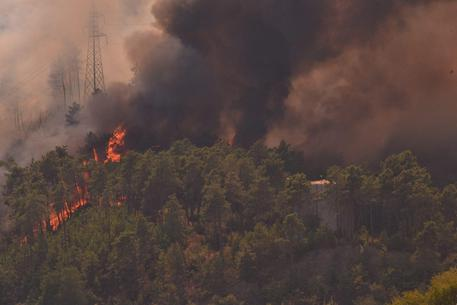

**Caption**: A wildfire in Italy. Can we predict which locations are most susceptible to wildfires using simple classifiers? 🔥

**Source**: [ANSA](https://www.ansa.it/english/news/2015/08/14/wildfires-in-italy-up-120-this-summer-on-past-two-years_f6e4eff7-ac07-4f9e-aa5a-e61f8c2ad7f2.html)

Let's start by downloading and loading the datasets into memory using the [`pooch`](https://pypi.org/project/pooch/) and [`GeoPandas`](https://geopandas.org/en/stable/) libraries:

In [2]:
# Install geopandas
%pip install geopandas

Note: you may need to restart the kernel to use updated packages.


In [3]:
import geopandas as gpd
import numpy as np
import pickle
import pooch

/Users/estelle/miniforge3/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [14]:
# Function to load the data
def load_data(path):

    # Load the content of the pickle file
    with open(path, "rb") as fh:
        points_df = pickle.load(fh)

    # L'ancienne colonne 'geometry' (sauvegardée avec un vieux geopandas) est inutilisable
    # avec les versions récentes : on la supprime, puis on la recrée à partir de x et y.
    points_df = pd.DataFrame(points_df).drop(columns="geometry", errors="ignore")

    # Convert it to a Geopandas `GeoDataFrame` for spatial analysis
    points_df = gpd.GeoDataFrame(points_df,
                                 geometry=gpd.points_from_xy(np.float64(points_df.x),
                                                             np.float64(points_df.y)))
    return points_df

In [15]:
# Fetch and cache verified snapshots of the Liguria wildfire dataset
WILDFIRE_FILES = {
    "points_liguria_vs0.1.pkl": "sha256:e8ebc70f972b5af4ef3d6110dcd61ce01ce5a830dcdb7d2c9e737aeab781606c",
    "fires_liguria_vs0.1.pkl": "sha256:361f067aafbac8add8f8a9a5c630df3c962cd37a2f125f420e7b9330fd0a1a4c",
}

In [16]:
def fetch_wildfire_file(filename):
    return pooch.retrieve(
        url=f"https://raw.githubusercontent.com/gse-unil/2026_MLEES_book/main/data/part-II/{filename}",
        known_hash=WILDFIRE_FILES[filename],
        fname=filename,
        path=pooch.os_cache("mlees"),
    )

In [17]:
variables_path = fetch_wildfire_file("points_liguria_vs0.1.pkl")
wildfires_path = fetch_wildfire_file("fires_liguria_vs0.1.pkl")

In [19]:
import sys, types
import pandas as pd
import pandas.core.indexes.base as _base
from pandas import Index

try:
    import pandas.core.indexes.numeric
except ImportError:
    sys.modules["pandas.core.indexes.numeric"] = types.ModuleType("pandas.core.indexes.numeric")
_numeric = sys.modules["pandas.core.indexes.numeric"]

# On met les anciennes classes dans LES DEUX modules
for name in ["Int64Index", "UInt64Index", "Float64Index", "NumericIndex"]:
    if not hasattr(_base, name):
        setattr(_base, name, Index)
    if not hasattr(_numeric, name):
        setattr(_numeric, name, Index)

import geopandas as gpd
# Les vieux pickles n'ont pas l'attribut `_sindex` (index spatial) : on lui donne une valeur par défaut
gpd.array.GeometryArray._sindex = None

variables = load_data(variables_path)
wildfires = load_data(wildfires_path)

/var/folders/4_/19fh9gx144j13yhqsvqk_vcw0000gn/T/ipykernel_48658/3693787446.py:6: DeprecationWarning: numpy.core.numeric is deprecated and has been renamed to numpy._core.numeric. The numpy._core namespace contains private NumPy internals and its use is discouraged, as NumPy internals can change without warning in any release. In practice, most real-world usage of numpy.core is to access functionality in the public NumPy API. If that is the case, use the public NumPy API. If not, you are using NumPy internals. If you would still like to access an internal attribute, use numpy._core.numeric._frombuffer.
  points_df = pickle.load(fh)
/var/folders/4_/19fh9gx144j13yhqsvqk_vcw0000gn/T/ipykernel_48658/3693787446.py:6: DeprecationWarning: numpy.core.numeric is deprecated and has been renamed to numpy._core.numeric. The numpy._core namespace contains private NumPy internals and its use is discouraged, as NumPy internals can change without warning in any release. In practice, most real-world us


## 🧠 Le principe en 1 minute (ce qu'on cherche à faire en machine learning)

**Type de méthode : classification supervisée (binaire).**

| Mot | Dans cet exercice |
|---|---|
| **Entrées `X`** (*features*) | les caractéristiques d'un point de la carte : altitude, pente, type de végétation, climat… |
| **Sortie `y`** (*label*, la « bonne réponse ») | `1` = il y a déjà eu un feu à cet endroit, `0` = non |
| **Supervisé** | on donne au modèle des exemples **avec** la bonne réponse, il en déduit une règle du genre « basse altitude + maquis + forte pente → souvent des feux » |
| **Classifieur** | le modèle (ici un *Random Forest*, un ensemble de nombreux arbres de décision qui votent) |
| **Jeu d'entraînement / de test** | on cache 20 % des points au modèle pendant l'apprentissage, puis on les utilise pour vérifier qu'il généralise, c'est-à-dire qu'il n'a pas juste appris par cœur |
| **Probabilité (`predict_proba`)** | au lieu de répondre « feu / pas feu », le modèle donne une probabilité entre 0 et 1 |
| **Carte de susceptibilité** | on colorie chaque point de la carte avec cette probabilité → on voit les zones les plus propices aux feux |

**Le déroulé de l'exercice :**

```
 variables (caractéristiques)  ──►  X (tableau de nombres)  ─┐
                                                              ├─► découpe train / test ─► entraîner le Random Forest
 wildfires (où y a-t-il eu des feux ?) ──►  y (0 / 1)  ──────┘                                   │
                                                                                                  ▼
            carte de susceptibilité  ◄──  probabilité de feu pour chaque point  ◄──  évaluer sur le jeu de test
```

Les trois étapes : **(I)** préparer `X` et `y` · **(II)** entraîner et évaluer le modèle · **(III)** utiliser le modèle pour dessiner la carte.


(previous_ex)=

### Part I: Pre-Processing the Dataset for Classification

**Q1) After analyzing the topography and land cover data provided in `variables`, create your input dataset `inputs` from `variables` to predict the occurence of wildfires (`wildfires`). Keep at least one categorical variable (`veg`, `bioclim`, or `phytoclim`).**

Hint 1: Refer to the documentation [at this link](https://github.com/mirkodandrea/liguria-fire-susceptibility/blob/master/variables%20explaination.md) to know what the different `keys` of `variables` refer to.

Hint 2: You may refer to Table 1 of [Tonini et al.](https://www.mdpi.com/2076-3263/10/3/105), copied below, to choose your input variables, although we recommend starting with less inputs at first to build a simpler model and avoid overfitting.

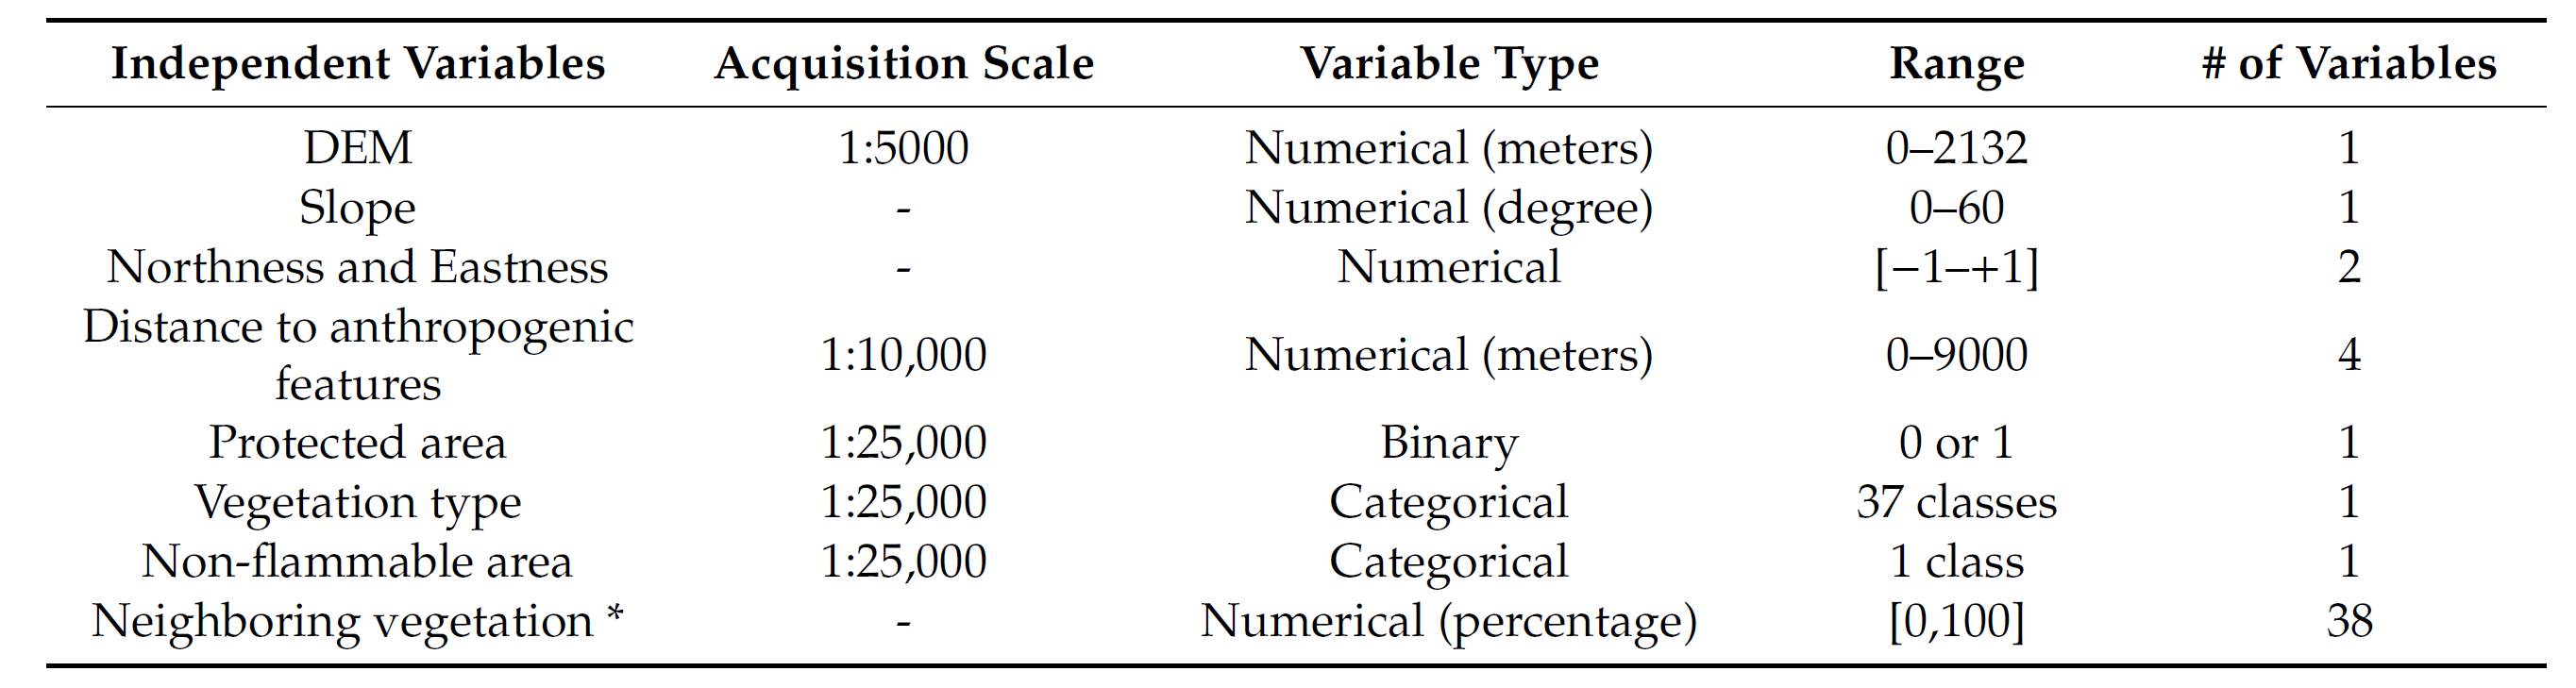

Here are some pandas commands you could use to explore your data.
[.head()](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.head.html)
[.columns()](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.columns.html)
[.describe()](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.describe.html)

In [20]:
# Explore the `variables` dataset
#########################################################################################################
# 1. What kind of data is provided in the "variables" panda DataFrame?
#########################################################################################################
# Can you print the variable names?
# -> chaque colonne est une caractéristique du terrain (dem = altitude, slope = pente, veg = végétation, ...)
print(variables.columns)

Index(['row', 'col', 'x', 'y', 'dem', 'slope', 'north', 'east', 'veg',
       'urban_d', 'roads_d', 'crops_d', 'tracks_d', 'bioclim', 'phytoclim',
       'temp_1', 'temp_2', 'prec_1', 'prec_2', 'perc_0', 'perc_21', 'perc_22',
       'perc_23', 'perc_32', 'perc_33', 'perc_34', 'perc_37', 'point_index',
       'geometry'],
      dtype='object')


In [21]:
# Can you print a table with all the statistics of each variable in the dataframe?
# -> describe() donne pour chaque colonne : moyenne, écart-type, min, max... utile pour repérer les ordres de grandeur
print(variables.describe())

                 row            col             x             y  \
count  528669.000000  528669.000000  5.286690e+05  5.286690e+05   
mean      456.389826     962.931258  1.475397e+06  4.901395e+06   
std       240.887463     555.848154  5.558482e+04  2.408875e+04   
min         1.000000       1.000000  1.379204e+06  4.848434e+06   
25%       256.000000     491.000000  1.428204e+06  4.882034e+06   
50%       411.000000     894.000000  1.468504e+06  4.905934e+06   
75%       650.000000    1463.000000  1.525404e+06  4.921434e+06   
max       986.000000    2065.000000  1.585604e+06  4.946934e+06   

                 dem          slope          north           east  \
count  528669.000000  528669.000000  528669.000000  528669.000000   
mean      538.422731      18.021345      -0.097896       0.017473   
std       336.707659       8.176142       0.701160       0.706036   
min         0.000000       0.000000      -1.000000      -1.000000   
25%       281.000000      12.281326      -0.787887 

There are 25 columns (variables) in the DataFrame. It is probably best to start simple and just use a few variables to make the wildfire prediction.

Can we use a very simple model to predict wildfires ❓

A simple model might contain `dem`, `slope`, `veg` and `bioclim`. We can use it as a baseline to evaluate model performance when you use other combinations to train the model.

However, we cannot tell you which combination would perform the best as we have not done an extensive search while preparing the notebook.

In [22]:
# Here you will filter the DataFrame so that only the variables you want are in the input
############################################################################################################
# 1. Drop down the names of variables you want here so that pandas can do the filtering for you.
############################################################################################################
# Chaque ligne de `variables` est un point géographique avec ses caractéristiques.
# On choisit ici les colonnes qui serviront d'ENTRÉES au modèle (modèle simple pour commencer) :
#   dem     = altitude (nombre)              slope   = pente (nombre)
#   veg     = type de végétation (CATÉGORIE) bioclim = zone bioclimatique (CATÉGORIE)
vars_tokeep = ['dem', 'slope', 'veg', 'bioclim']

In [23]:
############################################################################################################
# 2. Create a new dataframe 'inputs' with just the variables you want
############################################################################################################
inputs = variables[vars_tokeep]  # on ne garde que les 4 colonnes choisies (filter 'variables' dataframe)
inputs.head()                    # print the first few rows to make sure everything works fine

,dem,slope,veg,bioclim
point_index,,,,
0,563,20.843185,34,15
1,527,23.599121,34,15
2,525,26.699856,34,15
3,519,24.512413,34,15
4,532,20.421495,34,15


**Q2) To avoid making inaccurate assumptions about which types of vegetation and non-flammable area are most similar, convert your categorical inputs into one-hot vectors.**

Hint 1: You may use the [`fit_transform`](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OneHotEncoder.html#sklearn.preprocessing.OneHotEncoder.fit_transform) method of `scikit-learn`'s [`OneHotEncoder`](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OneHotEncoder.html) class to convert categorical inputs into one-hot vectors.

Hint 2: Don't forget to remove the categorical variables from your input dataset, e.g. using [`drop`](https://geopandas.org/en/stable/docs/reference/api/geopandas.GeoDataFrame.html) if you are still using a `GeoDataFrame`, or [`del`](https://docs.python.org/3/reference/simple_stmts.html#the-del-statement)/[`pop`](https://docs.python.org/3/library/stdtypes.html#dict.pop) if you are working with a Python dictionary.

Hint 3: There are numerous ways to change the categorical data into one-hot vectors. It is quite easy to do in `pandas`, but scikit-learn also provides some transformers that could be useful, including [.ColumnTransformer()](https://scikit-learn.org/stable/modules/generated/sklearn.compose.ColumnTransformer.html) and [Pipeline()](https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html).

In the guided reading, you have seen how these functions are used. Try experiment with them and see if you prefer using these scikit transformers or pandas.

In [26]:
############################################################################################################
# 1. Import OneHotEncoder for 'veg' and 'bioclim' data, and pandas
############################################################################################################
%pip install scikit-learn
from sklearn.preprocessing import OneHotEncoder
import pandas as pd
############################################################################################################
# 2. Initiate OneHotEncoder object, set the 'sparse_output' option to False
############################################################################################################
# POURQUOI le one-hot ? 'veg' et 'bioclim' sont des catégories codées par des numéros (1, 2, 3...).
# Si on les donne telles quelles, le modèle croirait que 3 > 2 > 1, ce qui n'a aucun sens pour des types de végétation.
# One-hot = une colonne par catégorie, avec un seul 1 (« hot ») et des 0 ailleurs. Ex. : catégorie 2 sur 3 -> [0, 1, 0]
#
# sparse_output=False : on veut un vrai tableau avec tous les 0 écrits (et pas une matrice « creuse »),
# pour pouvoir le transformer ensuite en DataFrame pandas.
enc = OneHotEncoder(sparse_output=False)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.3/8.3 MB 32.6 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [scikit-learn] [scikit-learn]
Note: you may need to restart the kernel to use updated packages.


In [27]:
############################################################################################################
# 3. Convert categorical variables into one-hot vectors
############################################################################################################
# fit_transform = (1) "fit" : l'encodeur repère toutes les catégories existantes, (2) "transform" : il crée les colonnes 0/1.
# variables[['veg']] avec DOUBLE crochets : on passe un tableau à 1 colonne (et pas une simple série), comme l'exige sklearn.
veg_onehot = enc.fit_transform(variables[['veg']])
bioclim_onehot = enc.fit_transform(variables[['bioclim']])   # on ré-utilise 'enc' : il est ré-appris pour bioclim
# Convert 'veg_onehot' and 'bioclim_onehot' to pandas DataFrames
veg_transform = pd.DataFrame(veg_onehot)     # veg : 1 colonne par type de végétation
bio_transform = pd.DataFrame(bioclim_onehot) # bioclim : 1 colonne par zone bioclimatique

In [28]:
############################################################################################################
# 4. Print the shape of 'veg_transform'
############################################################################################################
# shape = (nombre de points, nombre de catégories de végétation)
print(veg_transform.shape)
# Don't change these!
# Les préfixes servent juste à savoir d'où viennent les colonnes : v_0, v_1... (végétation), b_0, b_1... (bioclim)
veg_transform= veg_transform.add_prefix('v_')
bio_transform= bio_transform.add_prefix('b_')

(528669, 7)


In [29]:
############################################################################################################
# 5. Convert 'inputs' into Panda DataFrame and reset index to align with one-hot columns
############################################################################################################
# reset_index(drop=True) : on remet les lignes numérotées 0, 1, 2, ... pour que 'inputs' et les tableaux one-hot
# soient bien alignés ligne par ligne au moment de les coller côte à côte.
inputs_gdf = pd.DataFrame(inputs).reset_index(drop=True)
############################################################################################################
# 6. Add 'veg_transform' and 'bio_transform' into the inputs DataFrame
############################################################################################################
# axis=1 : on colle les colonnes côte à côte
inputs_gdf = pd.concat([inputs_gdf, veg_transform, bio_transform], axis=1)

In [ ]:
############################################################################################################
# 7. Use .drop() to delete 'veg' and 'bioclim' from DataFrame
############################################################################################################
# Les colonnes d'origine (codes 1, 2, 3...) sont remplacées par leurs versions one-hot -> on les supprime.
inputs_gdf = inputs_gdf.drop(columns=['veg', 'bioclim'], errors='ignore')
print(inputs_gdf.shape)   # = (nombre de points, 2 variables numériques + colonnes v_* + colonnes b_*)
inputs_gdf.head()

(528669, 14)


,dem,slope,v_0,v_1,v_2,v_3,v_4,v_5,v_6,b_0,b_1,b_2,b_3,b_4
0,563,20.843185,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0
1,527,23.599121,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0
2,525,26.699856,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0
3,519,24.512413,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0
4,532,20.421495,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0


Now that we built our `inputs` dataset, we are ready to build our `outputs` dataset!

**Q3) Using the `point_index` column of `wildfires` and `variables`, create your `outputs` dataset, containing 1 when there was a wildfire and 0 otherwise.**

Hint: Check that `inputs` and `outputs` have the same number of cases by looking at their `.shape[0]` attribute.

In [31]:
#####################################################################################################################
# 1. Comment relier `wildfires` et `variables` ?
#####################################################################################################################
# `wildfires` = la liste des feux observés. L'identifiant du point touché s'appelle 'point_index' :
# dans `wildfires` c'est l'INDEX (pas une colonne, d'où le KeyError 'point_index' si on écrit wildfires['point_index']),
# alors que dans `variables` c'est une COLONNE.
print("Colonnes du DataFrame 'wildfires' :", wildfires.columns)
print("Index du DataFrame 'wildfires' :", wildfires.index.name)
print(wildfires.head(2))
print("Nombre de lignes de wildfires :", len(wildfires), "| nombre de lignes de variables :", len(variables))

Colonnes du DataFrame 'wildfires' : Index(['x', 'y', 'fire_index', 'season', 'geometry'], dtype='object')
Index du DataFrame 'wildfires' : point_index
                        x             y  fire_index  season  \
point_index                                                   
1761         1.500504e+06  4.943934e+06      1761.0       2   
1851         1.500504e+06  4.943834e+06      1851.0       2   

                                    geometry  
point_index                                   
1761         POINT (1500504.192 4943934.406)  
1851         POINT (1500504.192 4943834.406)  
Nombre de lignes de wildfires : 81834 | nombre de lignes de variables : 528669


In [33]:
#####################################################################################################################
# 2. Créer un tableau de zéros : au départ, on suppose qu'aucun point n'a brûlé
#####################################################################################################################
outputs = np.zeros(len(variables), dtype=int)   # un 0 par ligne de `variables`
#####################################################################################################################
# 3. Fill the zero array with ones if a fire broke out at a specific location index.
# Here you can use a for loop for this task
#####################################################################################################################
fire_ids = set(wildfires.index)                 # identifiants (point_index) des points où il y a eu un feu
point_ids = variables['point_index'].to_numpy() # identifiant de chaque ligne de `variables`

# Attention : on ne peut pas écrire directement `outputs[idx] = 1` avec idx = point_index, car dans `variables`
# la POSITION de la ligne n'est pas toujours égale à son point_index (certains points apparaissent deux fois).
# On parcourt donc les lignes et on regarde, pour chacune, si son point_index figure dans la liste des feux.
for position, pid in enumerate(point_ids):
    if pid in fire_ids:
        outputs[position] = 1

# (Équivalent plus rapide, sans boucle :  outputs = np.isin(point_ids, wildfires.index).astype(int) )

In [34]:
#####################################################################################################################
# 4. Check that `inputs` and `outputs` have the same shape[0]
#####################################################################################################################
print("inputs :", inputs_gdf.shape[0], "lignes | outputs :", outputs.shape[0], "lignes")
assert inputs_gdf.shape[0] == outputs.shape[0]   # une réponse (0/1) pour chaque point
print(f"Part de points avec un feu : {outputs.mean():.1%}   (donc ~{1-outputs.mean():.0%} de 0 : classes DÉSÉQUILIBRÉES)")

inputs : 528669 lignes | outputs : 528669 lignes
Part de points avec un feu : 15.5%   (donc ~85% de 0 : classes DÉSÉQUILIBRÉES)



> 💡 **À retenir.** Environ 15 % des points ont brûlé et 85 % non. Un modèle « paresseux » qui répondrait toujours *« pas de feu »* aurait donc déjà ~85 % de bonne réponse. L'**accuracy** seule est donc trompeuse ici : on regardera aussi la **matrice de confusion** (Q6).


**Q4) Separate your `inputs` and `outputs` datasets into a training and a test set. Keep at least 20% of the dataset for testing.**

Hint 1: You may use `scikit-learn`'s [`train_test_split`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html) function.

Hint 2: If you are considering optimizing the hyperparameters of your classifier, form a validation dataset as well.

Hint 3: We recommend performing the split on the indices so that it is easier to track what points are in which dataset after splitting. You will have an easier time when plotting the susceptibility map.

In [35]:
#####################################################################################################################
# 1. Import train_test_split()
#####################################################################################################################
from sklearn.model_selection import train_test_split

In [36]:
#####################################################################################################################
# 2. Create a list with all indices in the input [0,1,2,...]
#####################################################################################################################
# On découpe les NUMÉROS de lignes (et pas directement les données) : ainsi on saura toujours quel point est dans
# quel jeu, ce qui sera pratique pour tracer la carte.
all_indices = list(range(len(inputs_gdf)))

In [37]:
#####################################################################################################################
# 3. Convert the inputs_gdf dataframe to numpy array
#####################################################################################################################
feature_names = list(inputs_gdf.columns)   # on mémorise les noms de colonnes (le numpy les perd), utile pour la suite
inputs_gdf = inputs_gdf.to_numpy()         # tableau numpy : plus simple à découper avec une liste d'indices

In [38]:
#####################################################################################################################
# 4. Apply train_test_split on 'all_indices', and store training indices in 'indx_train', test indices in 'indx_test'
#####################################################################################################################
# test_size=0.2 -> 20 % des points sont mis de côté pour tester (le modèle ne les verra JAMAIS pendant l'entraînement)
# random_state=42 -> tirage aléatoire reproductible (même découpe à chaque exécution)
indx_train, indx_test = train_test_split(all_indices, test_size=0.2, random_state=42)

In [39]:
#####################################################################################################################
# 5. Create training and test sets with indx_train and indx_test
#####################################################################################################################
# X = entrées (caractéristiques), y = sorties (0/1). On découpe les deux avec les MÊMES indices pour garder l'alignement.
X_train, X_test, y_train, y_test = inputs_gdf[indx_train], inputs_gdf[indx_test], outputs[indx_train], outputs[indx_test]

In [40]:
# Check the shape of your training(/validation)/test sets
# and make sure you kept at least 20% of your dataset for testing
print("Entraînement :", X_train.shape, y_train.shape)
print("Test         :", X_test.shape, y_test.shape)
print(f"Part du jeu de test : {len(y_test) / len(outputs):.0%}")

Entraînement : (422935, 14) (422935,)
Test         : (105734, 14) (105734,)
Part du jeu de test : 20%


Congratulations, you have created a viable wildfire dataset to train a machine learning classifier! 😃 Now let's get started 🔥

### Part II: Training and Benchmarking the Machine Learning Classifiers

**Q5) Now comes the machine learning fun! 🤖 Train multiple classifiers on your newly-formed training set, and make sure that at least one has the `predict_proba` method once trained.**

Hint: You may train a [`RandomForestClassifier`](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html) or an [`ExtraTreesClassifier`](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.ExtraTreesClassifier.html), but we encourage you to be creative and include additional classifiers you find promising! 💻

In [ ]:
# Autres classifieurs pour comparer avec le Random Forest (Q5).
# Tous sont SUPERVISÉS : ils apprennent à partir des entrées X et des bonnes réponses y (feu = 1 / pas de feu = 0),
# et tous ont une méthode predict_proba, donc on pourra en faire une carte de susceptibilité.
#   - Régression logistique : modèle simple et linéaire, sert de point de comparaison (StandardScaler = on met les
#     variables à la même échelle, car l'altitude et la pente n'ont pas les mêmes unités), attention que linéaire donc pas fou
#   - ExtraTrees : proche du Random Forest, mais avec des coupures d'arbres plus aléatoires (plus rapide).
#   - HistGradientBoosting : arbres construits l'un après l'autre, chacun corrigeant les erreurs du précédent. Attention surapprentissage du bruit
#.  - SVC ( kenrel = linear), trop linéaire et pas de predict proba il faut rajouter probability true = très lent, les autre SVC très lent rbf
# ,poly, potentiellemnt plus petit échantillon
# On les compare ensuite sur le jeu de test (Q6) avec l'accuracy et la matrice de confusion.

In [43]:
#####################################################################################################################
# 1. Import RandomForestClassifier
#####################################################################################################################
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
#####################################################################################################################
# 2. Convert X_train and X_test into pandas DataFrame
#####################################################################################################################
# (on remet les noms de colonnes : plus lisible, et nécessaire pour l'analyse d'importance des variables plus tard)
X_train = pd.DataFrame(X_train, columns=feature_names)
X_test = pd.DataFrame(X_test, columns=feature_names)


In [44]:
X_train

,dem,slope,v_0,v_1,v_2,v_3,v_4,v_5,v_6,b_0,b_1,b_2,b_3,b_4
0,143.0,3.441056,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
1,204.0,21.165070,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
2,304.0,28.740286,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
3,318.0,18.950947,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
4,522.0,19.906359,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
422930,431.0,14.090720,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
422931,560.0,3.790979,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
422932,213.0,19.034899,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
422933,413.0,0.955438,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0


In [45]:
#####################################################################################################################
# 3. Initiate RF classifier and fit it on training set
#####################################################################################################################
# Random Forest = beaucoup d'arbres de décision (ici 100) entraînés chacun sur un échantillon différent des données ;
# pour prédire, tous les arbres « votent ». C'est robuste et ça marche bien sans trop de réglages.
#   n_jobs=-1      : utilise tous les cœurs du processeur (plus rapide)
#   random_state=42: résultat reproductible
rfc = RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=42)
hgb = HistGradientBoostingClassifier(random_state=42)
# .fit(X, y) = L'APPRENTISSAGE : le modèle cherche les règles qui relient les caractéristiques X aux feux y.
# Il n'utilise QUE le jeu d'entraînement. (~30-60 s)
rfc.fit(X_train, y_train)
hgb.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NonePseudo-random number generator to control the subsampling in thebinning process, and the train/validation data split if early stoppingis enabled.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"loss loss: {'log_loss'}, default='log_loss'The loss function to use in the boosting process.For binary classification problems, 'log_loss' is also known as logistic loss,binomial deviance or binary crossentropy. Internally, the model fits one treeper boosting iteration and uses the logistic sigmoid function (expit) asinverse link function to compute the predicted positive class probability.For multiclass classification problems, 'log_loss' is also known as multinomialdeviance or categorical crossentropy. Internally, the model fits one tree perboosting iteration and per class and uses the softmax function as inverse linkfunction to compute the predicted probabilities of the classes.",'log_loss'
,"learning_rate learning_rate: float, default=0.1The learning rate, also known as *shrinkage*. This is used as amultiplicative factor for the leaves values. Use ``1`` for noshrinkage.",0.1
,"max_iter max_iter: int, default=100The maximum number of iterations of the boosting process, i.e. themaximum number of trees for binary classification. For multiclassclassification, `n_classes` trees per iteration are built.",100
,"max_leaf_nodes max_leaf_nodes: int or None, default=31The maximum number of leaves for each tree. Must be strictly greaterthan 1. If None, there is no maximum limit.",31
,"max_depth max_depth: int or None, default=NoneThe maximum depth of each tree. The depth of a tree is the number ofedges to go from the root to the deepest leaf.Depth isn't constrained by default.",None
,"min_samples_leaf min_samples_leaf: int, default=20The minimum number of samples per leaf. For small datasets with lessthan a few hundred samples, it is recommended to lower this valuesince only very shallow trees would be built.",20
,"l2_regularization l2_regularization: float, default=0The L2 regularization parameter penalizing leaves with small hessians.Use ``0`` for no regularization (default).",0.0
,"max_features max_features: float, default=1.0Proportion of randomly chosen features in each and every node split.This is a form of regularization, smaller values make the trees weakerlearners and might prevent overfitting.If interaction constraints from `interaction_cst` are present, only allowedfeatures are taken into account for the subsampling... versionadded:: 1.4",1.0
,"max_bins max_bins: int, default=255The maximum number of bins to use for non-missing values. Beforetraining, each feature of the input array `X` is binned intointeger-valued bins, which allows for a much faster training stage.Features with a small number of unique values may use less than``max_bins`` bins. In addition to the ``max_bins`` bins, one more binis always reserved for missing values. Must be no larger than 255.",255
,"categorical_features categorical_features: array-like of {bool, int, str} of shape (n_features) or shape (n_categorical_features,), default='from_dtype'Indicates the categorical features.- None : no feature will be considered categorical.- boolean array-like : boolean mask indicating categorical features.- integer array-like : integer indices indicating categorical features.- str array-like: names of categorical features (assuming the training data has feature names).- `""from_dtype""`: dataframe columns with dtype ""Categorical"" and ""Enum"" are considered to be categorical features. The input must be a dataframe that is supported by narwhals (or supports it): :func:`narwhals.from_native` must work. This is the case, for instance, for pandas and polars DataFrames.For each categorical feature, there must be at most `max_bins` uniquecategories. Negative values for categorical features encoded as numericdtypes are treated as missing val


> 💡 **Ce qui vient de se passer.** Le modèle a « regardé » ~420 000 exemples (X_train, y_train) et a construit 100 arbres de décision qui décrivent quelles combinaisons de caractéristiques vont avec un feu. Il n'a pas du tout vu le jeu de test : c'est lui qui va nous dire si le modèle sait **généraliser** à des points inconnus.


**Q6) Compare the performance and confusion matrices of your classifiers on the test set. Which classifier performs best in your case?**

Hint 1: You may use the [`accuracy_score`](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.accuracy_score.html) to quantify your classifier's performance, but don't forget there are [many other performance metrics to benchmark binary classifiers](https://scikit-learn.org/stable/modules/model_evaluation.html#classification-metrics).

Hint 2: You can directly calculate the confusion matrix using `scikit-learn`'s [`confusion_matrix` function](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.confusion_matrix.html).

In [46]:
#####################################################################################################################
# 1. Import accuracy_score, confusion_matrix, and ConfusionMatrixDisplay
#####################################################################################################################
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

In [47]:
#####################################################################################################################
# 2. Use rfc to make prediction on test set
#####################################################################################################################
# .predict(X) -> pour chaque point du jeu de test, le modèle répond 0 (pas de feu) ou 1 (feu)
rfc_preds = rfc.predict(X_test)
hgb_preds = hgb.predict(X_test)

In [48]:
#####################################################################################################################
# 3. Use accuracy_score to infer trained classifier performance
#####################################################################################################################
# accuracy = proportion de bonnes réponses (on compare les vraies réponses y_test aux prédictions)
rfc_acc = accuracy_score(y_test, rfc_preds)
print(f"Accuracy du Random Forest : {rfc_acc:.1%}")
print(f"Accuracy d'un modèle qui répondrait toujours 'pas de feu' : {1 - y_test.mean():.1%}")
print("Accuracy HGB :", accuracy_score(y_test, hgb_preds))

Accuracy du Random Forest : 85.3%
Accuracy d'un modèle qui répondrait toujours 'pas de feu' : 84.5%
Accuracy HGB : 0.8546730474587172


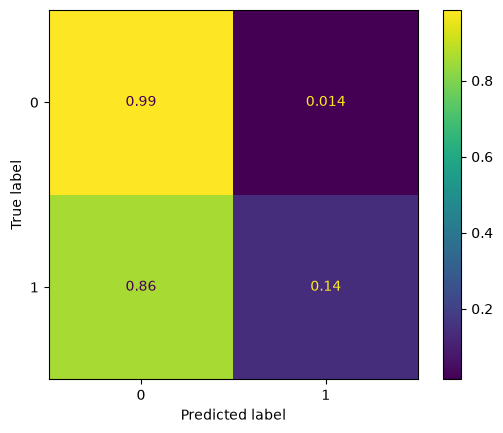

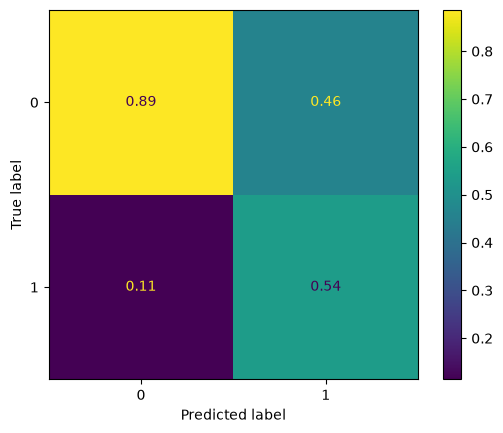

In [49]:
#####################################################################################################################
# 4. Plot the confusion matrix
#####################################################################################################################
# Matrice de confusion : lignes = réalité, colonnes = prédiction du modèle
#   [ vrai négatif   faux positif ]      (0 = pas de feu, 1 = feu)
#   [ faux négatif   vrai positif ]
# normalize='pred' : chaque COLONNE est ramenée à 100 % -> on lit « quand le modèle prédit X, a-t-il raison ? »
cm = confusion_matrix(y_test, rfc_preds, normalize='pred') # Get a confusion matrix 'cm', use 'pred' for the normalize option
disp = ConfusionMatrixDisplay(confusion_matrix = cm) # Use ConfusionMatrixDisplay to visualize 'cm'
ConfusionMatrixDisplay(confusion_matrix=confusion_matrix(y_test, hgb_preds, normalize='true')).plot()
disp.plot()

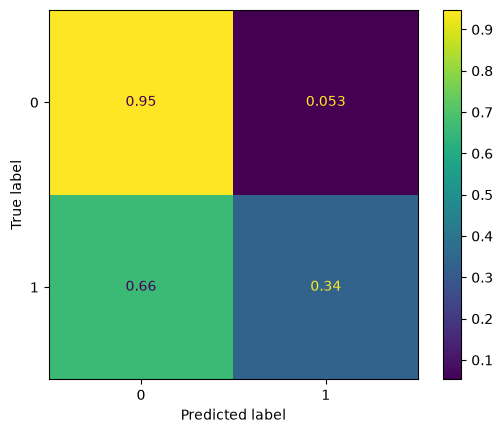

In [50]:

# Même chose avec normalize='true' : chaque LIGNE est ramenée à 100 % -> on lit « parmi les vrais feux
# (ou les vrais non-feux), quelle part le modèle a-t-il bien retrouvée ? » (la ligne du bas = part des feux détectés)
cm_true = confusion_matrix(y_test, rfc_preds, normalize='true')
ConfusionMatrixDisplay(confusion_matrix=cm_true).plot()



> 💡 **Comment lire ces résultats.** L'accuracy est tout juste meilleure que celle du modèle « toujours pas de feu », et la 2ᵉ matrice montre qu'une grande partie des vrais feux n'est **pas** retrouvée : avec seulement 4 variables, le modèle est trop simple (c'est exactement ce que dit l'énoncé plus bas). Pour progresser, il faut de meilleures variables d'entrée, pas un « meilleur » algorithme : voir le bonus.


For comparison, below is the confusion matrix obtained by the paper's authors:


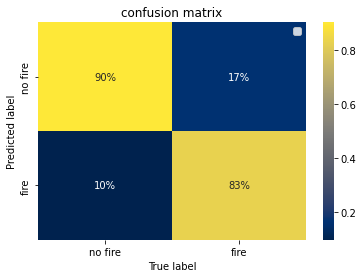

### Part III: Making the Susceptibility Map

**Q7) Using all the classifiers you trained that have a `predict_proba` method, predict the probability of a wildfire over the entire dataset.**

Hint: `predict_proba` will give you the probability of both the presence and absence of a wildfire, so you will have to select the right probability.

In [55]:
#####################################################################################################################
# 1. Predict the probability of a wildfire or not on the *entire* dataset
#####################################################################################################################
# predict_proba renvoie 2 colonnes : [probabilité de "pas de feu", probabilité de "feu"] pour CHAQUE point.
# On le fait sur TOUS les points de la région (pas seulement le test) pour pouvoir dessiner une carte complète.
predprob_rf = rfc.predict_proba(pd.DataFrame(inputs_gdf, columns=feature_names)) # Use .predict_proba in the 'rfc' classifier to process the entire dataset
prob_hgb = hgb.predict_proba(pd.DataFrame(inputs_gdf, columns=feature_names))[:, 1]


In [56]:
#####################################################################################################################
# 2. Extract the probability of a wildfire happening over the entire period of the dataset for each instance
#####################################################################################################################
# [:, 1] = "toutes les lignes, colonne n°1" = la probabilité de FEU (la colonne 0 étant la probabilité de pas de feu)
rf_testprob_fire = predprob_rf[:, 1] # Hint: predprob_rf shape = [:,2], select the second column

**Q8) Make the susceptibility map 🔥**

Hint 1: The `x` and `y` coordinates for the map can be extracted from the `variables` dataset.

Hint 2: You can simply [`scatter`](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.scatter.html) `x` versus `y`, and color the dots according to their probabilities (`c`=probability of a wildfire) to get the susceptibility map.

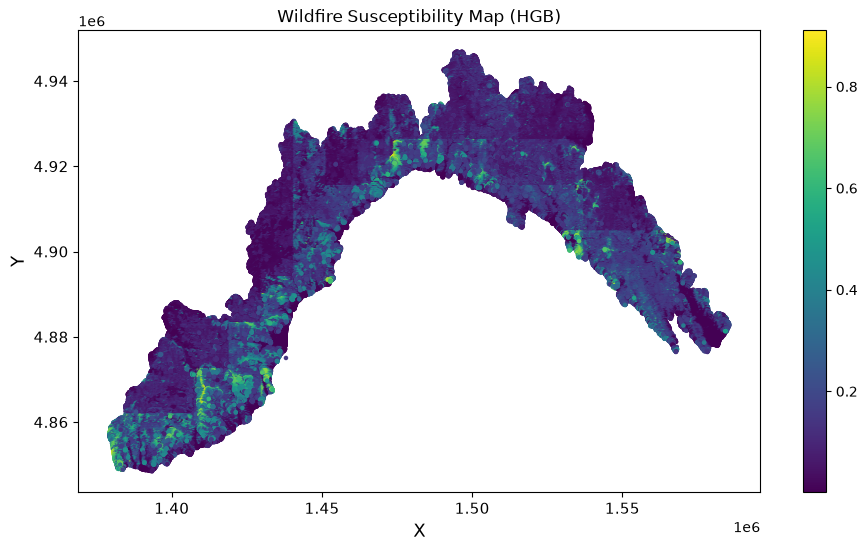

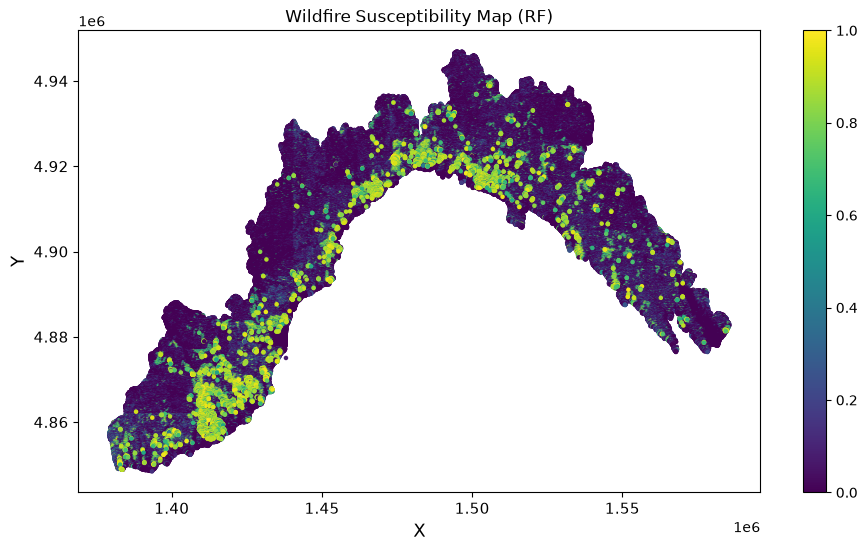

In [59]:
# Scatter ['x'] vs ['y'] columns in the entire dataframe and color the dots with the predicted probability 'rf_testprob_fire'
# to make the susceptibility map

import matplotlib.pyplot as plt
# 1 point = 1 lieu de la Ligurie (position x, y) ; sa couleur = probabilité de feu prédite par le modèle
fig,ax = plt.subplots(1,figsize=(6+5,4+2))
cmploy = ax.scatter(variables['x'],variables['y'],s=5,c=prob_hgb,cmap='viridis')
plt.colorbar(cmploy,ax=ax)
ax.set_title('Wildfire Susceptibility Map (HGB)')
ax.set_ylabel('Y',size=13)
ax.set_xlabel('X',size=13)
ax.tick_params(axis='both', which='major', labelsize=11)
plt.show()

# Scatter ['x'] vs ['y'] columns in the entire dataframe and color the dots with the predicted probability 'rf_testprob_fire'
# to make the susceptibility map

import matplotlib.pyplot as plt
# 1 point = 1 lieu de la Ligurie (position x, y) ; sa couleur = probabilité de feu prédite par le modèle
fig,ax = plt.subplots(1,figsize=(6+5,4+2))
cmploy = ax.scatter(variables['x'],variables['y'],s=5,c=rf_testprob_fire,cmap='viridis')
plt.colorbar(cmploy,ax=ax)
ax.set_title('Wildfire Susceptibility Map (RF)')
ax.set_ylabel('Y',size=13)
ax.set_xlabel('X',size=13)
ax.tick_params(axis='both', which='major', labelsize=11)
plt.show()


> 💡 **Comment lire la carte.** Jaune = probabilité de feu élevée, violet = faible. Attention : cette carte inclut aussi les points d'entraînement, que le modèle a déjà « vus » ; elle est donc un peu optimiste. La vraie mesure de qualité reste l'évaluation sur le jeu de test (Q6).


You should get a susceptibility map that looks like the one below. Does your susceptibility map depend on the classifier & the inputs you chose? Which map would you trust most?

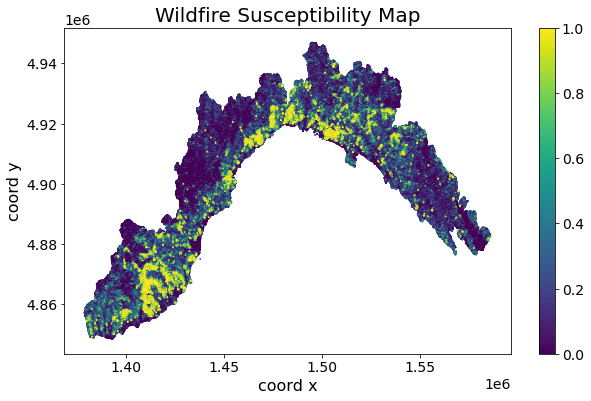

It seems like our model was too simple to generate a useful map 😞 .
Your TA actually experimented training a RandomForest model with 10 variables and got a 91% accuracy!

So you should definitely try combinations of different variables to get a map that is better than what you just got.

## Bonus Exercise 4: Exploring the Susceptibility Map's Sensitivity to Seasonality and Input Selection

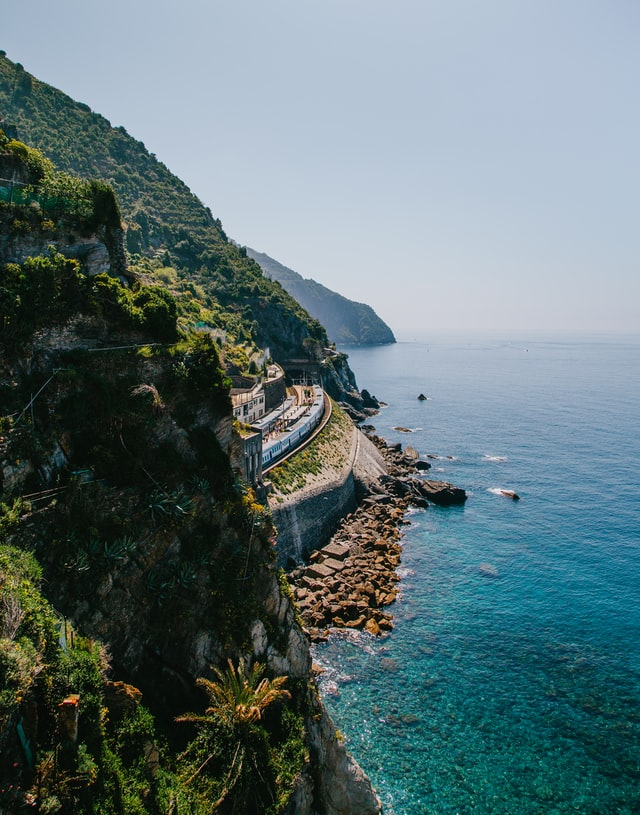

**Caption:** The Liguria region (Cinque Terre), after you save it from raging wildfires using machine learning ✌

### Part I: Seasonality


> 💡 **Idée du bonus.** Avec le modèle simple, la carte était décevante. Ici on cherche à (1) voir si les zones à risque diffèrent entre l'**hiver** et l'**été**, puis (2) trouver **quelles variables comptent vraiment** pour garder un modèle simple et fiable. On réutilise exactement la même recette (X, y → Random Forest → `predict_proba` → carte), rangée dans des petites **fonctions** pour ne pas recopier le code.


**Q1) Using the `season` column of `wildfires`, separate your data into two seasonal datasets (1=Winter, 2=Summer).**

Hint: When splitting your `inputs` into two seasonal datasets, keep in mind that `temp_1` and `prec_1` are the climatological mean temperatures and precipitation during winter, while `temp_2` and `prec_2` are the climatological mean temperature and precipitation during summer.  

In [39]:
# Identify indices for which the wildfires occured during winter/summer
# `wildfires['season']` : 1 = hiver, 2 = été. Rappel : l'identifiant du point est l'INDEX de `wildfires`.
winter_fire_idx = wildfires.index[wildfires['season'] == 1]
summer_fire_idx = wildfires.index[wildfires['season'] == 2]
print("Feux en hiver :", len(winter_fire_idx), "| feux en été :", len(summer_fire_idx))

# Dans `variables`, un point qui a brûlé en hiver ET en été apparaît 2 fois. Pour le bonus, on veut 1 ligne par
# point : on garde donc la liste des points uniques.
points = variables.drop_duplicates(subset='point_index').reset_index(drop=True)
print("Points uniques :", len(points))

Feux en hiver : 45991 | feux en été : 35843
Points uniques : 519472


In [40]:
# Use these indices to split your `inputs` and `outputs` datasets
# into two seasonal datasets

# Variables d'entrée proposées (on retire les coordonnées et les identifiants, qui ne sont pas des caractéristiques du terrain)
continuous_vars  = ['dem', 'slope', 'north', 'east', 'urban_d', 'roads_d', 'crops_d', 'tracks_d',
                    'perc_0', 'perc_21', 'perc_22', 'perc_23', 'perc_32', 'perc_33', 'perc_34', 'perc_37']
categorical_vars = ['veg', 'bioclim', 'phytoclim']

def make_dataset(season):
    """Construit (X, y) pour une saison : 1 = hiver, 2 = été."""
    X = points[continuous_vars].copy()
    # Température et précipitations existent en 2 versions (_1 = hiver, _2 = été) :
    # on garde celle de la saison étudiée, sous un nom commun.
    X['temp'] = points[f'temp_{season}']
    X['prec'] = points[f'prec_{season}']
    # Variables catégorielles -> one-hot (comme dans l'exercice précédent)
    for col in categorical_vars:
        onehot = OneHotEncoder(sparse_output=False).fit_transform(points[[col]])
        X = pd.concat([X, pd.DataFrame(onehot, columns=[f"{col}_{i}" for i in range(onehot.shape[1])])], axis=1)
    # Sortie : 1 si CE point a brûlé pendant CETTE saison, 0 sinon
    fire_idx = wildfires.index[wildfires['season'] == season]
    y = points['point_index'].isin(fire_idx).astype(int).to_numpy()
    return X, y

X_winter, y_winter = make_dataset(1)
X_summer, y_summer = make_dataset(2)

In [41]:
# Verify that for each season, the shape[0] of your
# `inputs` and `outputs` sets are the same
print("Hiver :", X_winter.shape, y_winter.shape, f"| part de points avec feu : {y_winter.mean():.1%}")
print("Été   :", X_summer.shape, y_summer.shape, f"| part de points avec feu : {y_summer.mean():.1%}")
assert X_winter.shape[0] == y_winter.shape[0] and X_summer.shape[0] == y_summer.shape[0]

Hiver : (519472, 42) (519472,) | part de points avec feu : 8.9%
Été   : (519472, 42) (519472,) | part de points avec feu : 6.9%


**Q2) Use these two seasonal datasets to make the Liguria winter and summer susceptibility maps using your best classifier(s). What do you notice?**

Hint: Feel free to recycle as much code as you can from [the previous exercise](#previous_ex). For instance, you may build a library of functions that directly train the classifier(s) and output susceptibility maps!

In [42]:
# So
# Fonction « tout-en-un » : découpe train/test, entraîne un Random Forest, affiche ses performances.
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

def train_and_evaluate(X, y, n_trees=50, name=""):
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=42)
    model = RandomForestClassifier(n_estimators=n_trees, min_samples_leaf=5, n_jobs=-1, random_state=42)  # min_samples_leaf=5 : arbres plus petits => moins de mémoire
    model.fit(X_tr, y_tr)                                  # apprentissage sur 80 % des points
    preds = model.predict(X_te)                            # prédictions sur les 20 % restants
    print(f"[{name}] accuracy test : {accuracy_score(y_te, preds):.1%}"
          f"  (modèle « jamais de feu » : {1 - y_te.mean():.1%})")
    print(f"[{name}] part des vrais feux retrouvés (rappel) : {confusion_matrix(y_te, preds, normalize='true')[1, 1]:.1%}")
    return model, X_te, y_te

In [43]:
# Much
# Fonction qui dessine une carte de susceptibilité à partir d'un vecteur de probabilités (1 valeur par point)
import matplotlib.pyplot as plt

def plot_susceptibility_map(prob, title, ax):
    sc = ax.scatter(points['x'], points['y'], s=1, c=prob, cmap='viridis', vmin=0, vmax=1)
    ax.set_title(title)
    ax.set_xlabel('X'); ax.set_ylabel('Y')
    return sc

In [44]:
# Recycling
# On entraîne un modèle par saison, puis on calcule la probabilité de feu sur tous les points
rf_winter, Xte_winter, yte_winter = train_and_evaluate(X_winter, y_winter, name="hiver")
rf_summer, Xte_summer, yte_summer = train_and_evaluate(X_summer, y_summer, name="été")

prob_winter = rf_winter.predict_proba(X_winter)[:, 1]
prob_summer = rf_summer.predict_proba(X_summer)[:, 1]

[hiver] accuracy test : 94.6%  (modèle « jamais de feu » : 91.1%)
[hiver] part des vrais feux retrouvés (rappel) : 41.8%


[été] accuracy test : 95.5%  (modèle « jamais de feu » : 93.2%)
[été] part des vrais feux retrouvés (rappel) : 35.8%


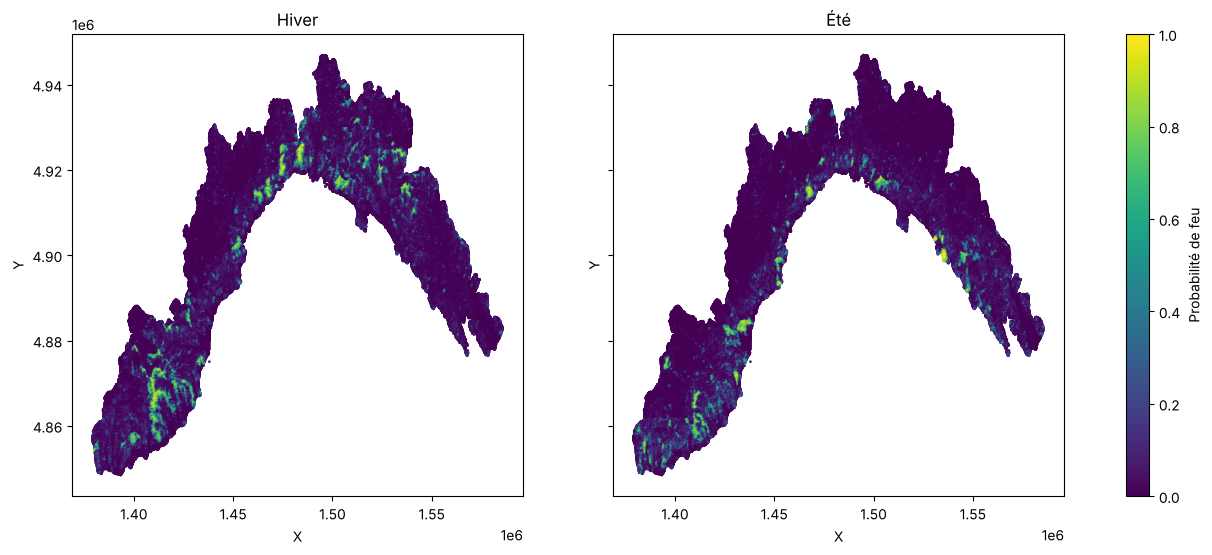

In [45]:
# Compare the winter and summer susceptibility maps
# Même échelle de couleurs (0 à 1) pour les deux cartes : on peut ainsi les comparer honnêtement
fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharex=True, sharey=True)
plot_susceptibility_map(prob_winter, 'Hiver', axes[0])
sc = plot_susceptibility_map(prob_summer, 'Été', axes[1])
fig.colorbar(sc, ax=axes, label='Probabilité de feu')
plt.show()

> 💡 **Ce qu'on observe.** Les zones à risque ne sont pas les mêmes selon la saison : en hiver les probabilités fortes sont plus étendues (davantage de feux : 8,9 % des points contre 6,9 % en été), alors qu'en été elles sont plus localisées. Une piste d'explication : le climat saisonnier (`temp`, `prec`) n'est pas le même, et les causes des feux peuvent différer. Un modèle par saison est donc plus pertinent qu'un seul modèle annuel.

Note : les scores restent modestes (le rappel, c'est-à-dire la part des vrais feux retrouvés, est d'environ 36 à 42 %), mais bien meilleurs que le modèle à 4 variables.

### Part II: Input Selection

The details of the susceptibility map may strongly depend on the inputs you chose from the `variables` dataset. Here, we explore two different ways of selecting inputs to make our susceptibility maps as robust as possible.

**Q3) Using your best classifier, identify the inputs contributing the most to your model's performance using [permutation feature importance](https://scikit-learn.org/stable/modules/permutation_importance.html).**

Hint: You may use `scikit-learn`'s [`permutation_importance` function](https://scikit-learn.org/stable/modules/generated/sklearn.inspection.permutation_importance.html) using your best classifier as your `estimator`.

In [46]:
# Import the necessary functions and classes
from sklearn.inspection import permutation_importance

In [47]:
# Calculate the permutation importance of each of your model's inputs
# Principe : on MÉLANGE au hasard les valeurs d'UNE variable dans le jeu de test et on regarde de combien le score baisse.
# Si le score chute beaucoup, le modèle s'appuyait beaucoup sur cette variable -> elle est importante.
# (Pour aller vite on utilise un sous-échantillon de 15 000 points du jeu de test. Score = AUC, plus fiable que
#  l'accuracy quand les classes sont déséquilibrées.)
rng = np.random.RandomState(42)
sel = rng.choice(len(Xte_winter), size=15000, replace=False)
perm = permutation_importance(rf_winter, Xte_winter.iloc[sel], yte_winter[sel],
                              scoring='roc_auc', n_repeats=3, random_state=42, n_jobs=1)

In [48]:
# Tableau trié : variable -> baisse moyenne du score quand on la mélange
importances = pd.Series(perm.importances_mean, index=Xte_winter.columns).sort_values(ascending=False)
importances.head(10)

temp        0.065424
prec        0.060773
dem         0.040705
perc_37     0.040499
crops_d     0.021640
urban_d     0.018610
north       0.017698
tracks_d    0.016142
roads_d     0.016110
slope       0.016045
dtype: float64

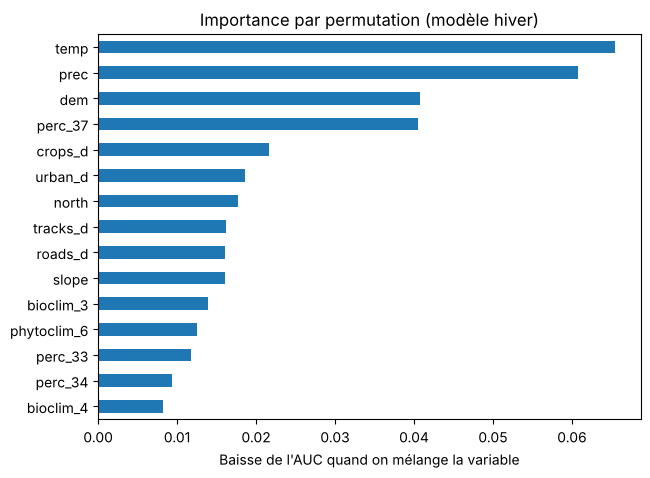

Variables retenues : ['temp', 'prec', 'dem', 'perc_37', 'crops_d', 'urban_d']


In [49]:
# Display the result and identify the most important inputs
importances.head(15)[::-1].plot.barh(figsize=(7, 5))
plt.xlabel("Baisse de l'AUC quand on mélange la variable")
plt.title("Importance par permutation (modèle hiver)")
plt.show()

top_features = importances.index[:6].tolist()   # on garde les 6 variables les plus importantes
print("Variables retenues :", top_features)

**Q4) Retrain the same type of classifier only using the inputs you identified as most important, and display the new susceptibility map.**

Hint: Feel free to recycle as much code as you can from [the previous exercise](#previous_ex). For instance, you may build a library of functions that directly train the classifier(s) and output susceptibility maps!

In [50]:
# Lots
# On ré-entraîne le MÊME type de modèle (Random Forest) mais seulement avec les variables les plus importantes
rf_winter_top, Xte_winter_top, yte_winter_top = train_and_evaluate(X_winter[top_features], y_winter, name="hiver, variables top")

[hiver, variables top] accuracy test : 94.6%  (modèle « jamais de feu » : 91.1%)
[hiver, variables top] part des vrais feux retrouvés (rappel) : 43.6%


In [51]:
# of
# Pour comparer : rappel du modèle avec toutes les variables (voir plus haut). Si les scores sont proches,
# les variables écartées n'apportaient presque rien.
print("Nombre de variables : toutes =", X_winter.shape[1], "| gardées =", len(top_features))

Nombre de variables : toutes = 42 | gardées = 6


In [52]:
# recycling
prob_winter_top = rf_winter_top.predict_proba(X_winter[top_features])[:, 1]

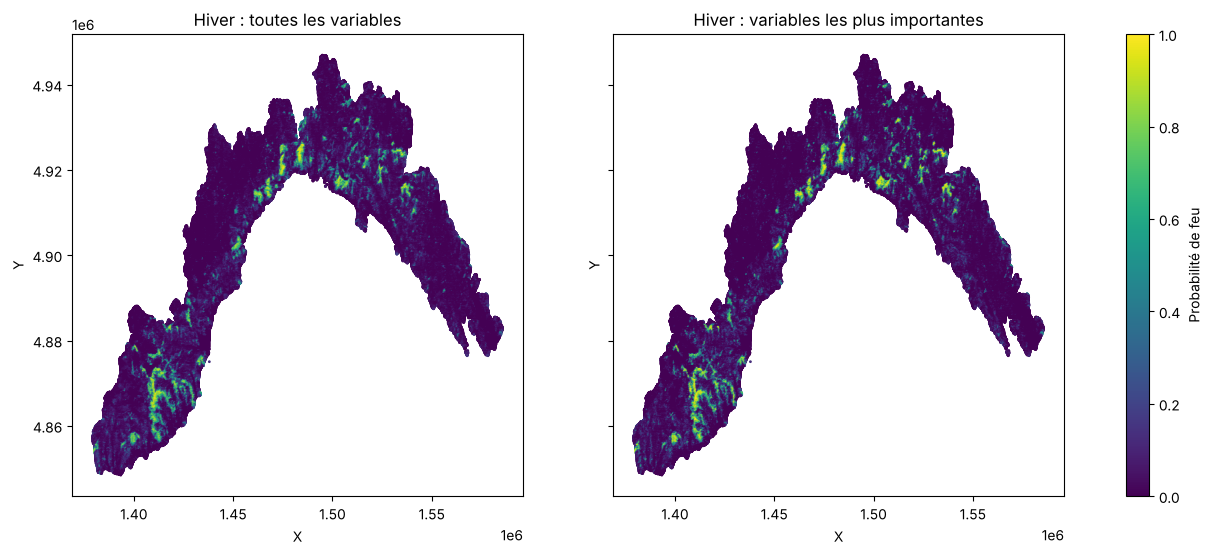

In [53]:
# Make the new susceptibility map
fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharex=True, sharey=True)
plot_susceptibility_map(prob_winter, 'Hiver : toutes les variables', axes[0])
sc = plot_susceptibility_map(prob_winter_top, 'Hiver : variables les plus importantes', axes[1])
fig.colorbar(sc, ax=axes, label='Probabilité de feu')
plt.show()

> 💡 **Ce qu'on observe.** Avec seulement 6 variables sur 42 (`temp`, `prec`, `dem`, `perc_37`, `crops_d`, `urban_d`), le score est quasi identique à celui du modèle complet (rappel même un peu meilleur). Les autres variables n'apportaient donc presque rien : on peut simplifier sans perdre en qualité. Les cartes se ressemblent car les variables importantes (altitude, climat, distance aux zones agricoles/urbaines) varient de façon lisse dans l'espace.

Can you explain the differences in susceptibility maps based on the inputs' spatial distribution?

If the susceptibility map changed a lot, our best classifier may initially have learned spurious correlations. This would have affected our permutation feature importance analysis, and motivates re-selecting our inputs from scratch! 🔨

**Q5) Use the [`SequentialFeatureSelector`](https://scikit-learn.org/stable/modules/generated/sklearn.feature_selection.SequentialFeatureSelector.html) to select the most important inputs. Select as few as possible!**

Hint: Track how the score improves as you add more and more inputs via `n_features_to_select`, and stop when it's "good enough".

In [54]:
# Import the SequentialFeatureSelector
# Principe (« forward selection ») : on part sans aucune variable, puis à chaque étape on ajoute celle qui améliore
# le plus le score (évalué par validation croisée), jusqu'à en avoir n_features_to_select.
from sklearn.feature_selection import SequentialFeatureSelector

In [55]:
# Add more and more inputs
# Pour que ce soit rapide, on utilise un petit modèle (arbres peu profonds) et un sous-échantillon de 10 000 points.
idx = np.random.RandomState(0).choice(len(X_winter), size=10000, replace=False)
X_small, y_small = X_winter.iloc[idx], y_winter[idx]
light_rf = RandomForestClassifier(n_estimators=10, max_depth=6, n_jobs=-1, random_state=0)

from sklearn.model_selection import cross_val_score
sfs_scores, sfs_selected = {}, {}
for n in [1, 2, 3, 4, 6]:
    sfs = SequentialFeatureSelector(light_rf, n_features_to_select=n, direction='forward',
                                    scoring='roc_auc', cv=2, n_jobs=-1)
    sfs.fit(X_small, y_small)
    cols = X_small.columns[sfs.get_support()].tolist()
    # score du modèle léger avec uniquement ces variables (validation croisée)
    sfs_scores[n] = cross_val_score(light_rf, X_small[cols], y_small, scoring='roc_auc', cv=3).mean()
    sfs_selected[n] = cols
    print(n, "variable(s) -> AUC =", round(sfs_scores[n], 3), cols)

1 variable(s) -> AUC = 0.675 ['perc_37']


2 variable(s) -> AUC = 0.711 ['dem', 'perc_37']


3 variable(s) -> AUC = 0.749 ['dem', 'crops_d', 'perc_37']


4 variable(s) -> AUC = 0.775 ['dem', 'crops_d', 'perc_37', 'temp']


6 variable(s) -> AUC = 0.774 ['dem', 'crops_d', 'perc_0', 'perc_37', 'temp', 'bioclim_4']


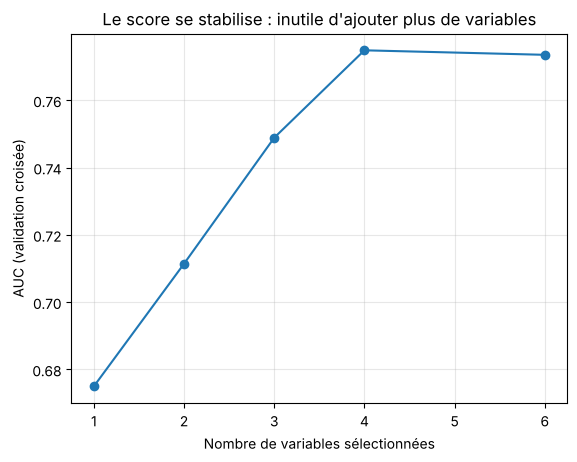

In [56]:
# How many inputs do you need to get a "good enough" score?
plt.plot(list(sfs_scores.keys()), list(sfs_scores.values()), 'o-')
plt.xlabel("Nombre de variables sélectionnées"); plt.ylabel("AUC (validation croisée)")
plt.title("Le score se stabilise : inutile d'ajouter plus de variables")
plt.grid(alpha=.3); plt.show()

> 💡 **Lecture de la courbe.** L'AUC monte nettement jusqu'à 4 variables (≈ 0,775), puis ne progresse plus avec 6 : 4 variables suffisent (`dem`, `crops_d`, `perc_37`, `temp`). La sélection séquentielle part de zéro et ne dépend pas d'un modèle déjà entraîné : c'est ce qui la protège des corrélations parasites qu'une première analyse par permutation aurait pu retenir. Ici, les 4 variables retenues figurent aussi dans le top 6 de la permutation (qui ajoutait `prec` et `urban_d`) : les deux méthodes se rejoignent.

Which inputs have you identified as the most important? Are they the same as the ones you selected using permutation feature importance?

**Q6) Retrain the same type of classifier using as little inputs as possible, and display the new susceptibility map.**

Hint: Feel free to recycle as much code as you can from [the previous exercise](#previous_ex). For instance, you may build a library of functions that directly train the classifier(s) and output susceptibility maps!

In [57]:
# Recycle your previous code here
# On choisit le plus petit nombre de variables à partir duquel le score ne progresse presque plus (voir la courbe)
n_best = 4
final_features = sfs_selected[n_best]
print("Variables retenues :", final_features)

Variables retenues : ['dem', 'crops_d', 'perc_37', 'temp']


In [58]:
# and here
rf_final, Xte_final, yte_final = train_and_evaluate(X_winter[final_features], y_winter, name="hiver, sélection SFS")
prob_final = rf_final.predict_proba(X_winter[final_features])[:, 1]

[hiver, sélection SFS] accuracy test : 92.0%  (modèle « jamais de feu » : 91.1%)
[hiver, sélection SFS] part des vrais feux retrouvés (rappel) : 18.4%


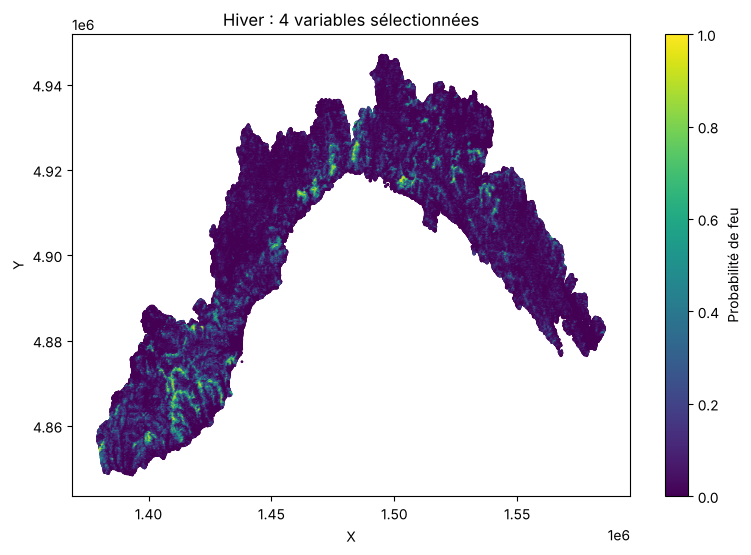

In [59]:
# And remake the final susceptibility map
fig, ax = plt.subplots(figsize=(9, 6))
sc = plot_susceptibility_map(prob_final, f'Hiver : {n_best} variables sélectionnées', ax)
fig.colorbar(sc, ax=ax, label='Probabilité de feu')
plt.show()

> 💡 **Bilan.** Avec 4 variables seulement, la carte est plus « lisse » et le rappel baisse (≈ 18 %) par rapport aux modèles à 6 ou 42 variables : simplicité contre précision. Le modèle de l'étude originale (10 variables, ~91 % d'accuracy) reste meilleur : le compromis se situe entre 4 et 10 variables. À vous d'essayer d'autres combinaisons.

**Récap des notions de ML vues :** classification supervisée · features (X) et label (y) · one-hot · jeu d'entraînement / de test · Random Forest · accuracy vs matrice de confusion (classes déséquilibrées) · `predict_proba` → carte · importance par permutation · sélection séquentielle de variables.

How does it compare to the authors' susceptibility map below?

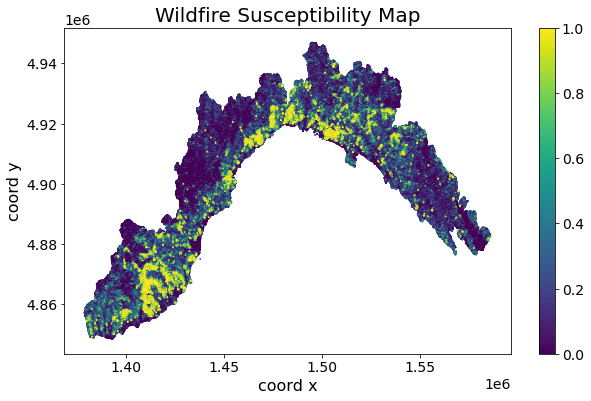